In [24]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [25]:
# define state
class BMIState(TypedDict):
    weight_kg:float
    height_m:float
    bmi:float
    catergory:str

In [26]:
def calculate_bmi(state: BMIState) -> BMIState:
    weight=state['weight_kg']
    height=state['height_m']
    bmi=(weight/height**2)
    state['bmi']=round(bmi,2)
    
    return state

def label_bmi(state:BMIState) -> BMIState:
    if state['bmi'] <18.5:
        state['catergory']="Underweight"
    elif 18.5<=state['bmi']<25:
        state['catergory']="Normal"
    elif 25<=state['bmi']<30:
        state['catergory']="Overweight"
    else:
        state['catergory']="Obese"
        
    return state

In [27]:
# define your graph 
graph = StateGraph(BMIState)

# add nodes
graph.add_node("calculate_BMI",calculate_bmi)
graph.add_node("label_bmi",label_bmi)

# add edges
graph.add_edge(START,'calculate_BMI')
graph.add_edge('calculate_BMI','label_bmi')
graph.add_edge('label_bmi',END)

# compile 
workflow=graph.compile()



In [28]:
# execute

initial_state={'height_m':1.73,'weight_kg':60}
final_state=workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 60, 'height_m': 1.73, 'bmi': 20.05, 'catergory': 'Normal'}


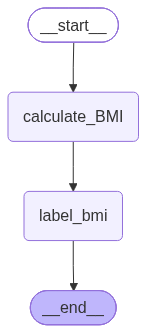

In [29]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())